#
Imports and File Upload

In [47]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [48]:
filepath='/content/sample_data/Student_Depression_Dataset.csv'
df=pd.read_csv(filepath)


#
Data Check

In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   object 
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   object 
 3   Relationship_status  4464 non-null   object 
 4   Marital_status       4464 non-null   object 
 5   Living_style         4464 non-null   object 
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   object 
 9   Health_condition     4464 non-null   object 
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   object 
 12  Depression           4464 non-null   object 
dtypes: float64(1), int64(3), object(9)
memory usage: 453.5+ KB


In [50]:
df.shape

(4464, 13)

In [51]:
df.describe()

,Age,Current_semester,CGPA,Cost_without_study
count,4464.000000,4464.000000,4464.000000,4464.000000
mean,22.619176,5.401210,3.412753,11242.978271
std,2.022980,2.578476,0.385605,6640.144019
min,17.000000,0.000000,2.250000,0.000000
25%,21.000000,3.000000,3.150000,6100.000000
50%,23.000000,5.000000,3.490000,9500.000000
75%,24.000000,7.000000,3.700000,15439.000000
max,28.000000,13.000000,4.000000,32000.000000


#
NUM and CAT cols

In [52]:
num_cols=df.select_dtypes(include='number').columns
cat_cols=df.select_dtypes(include='object').columns

#
Outlier Handling

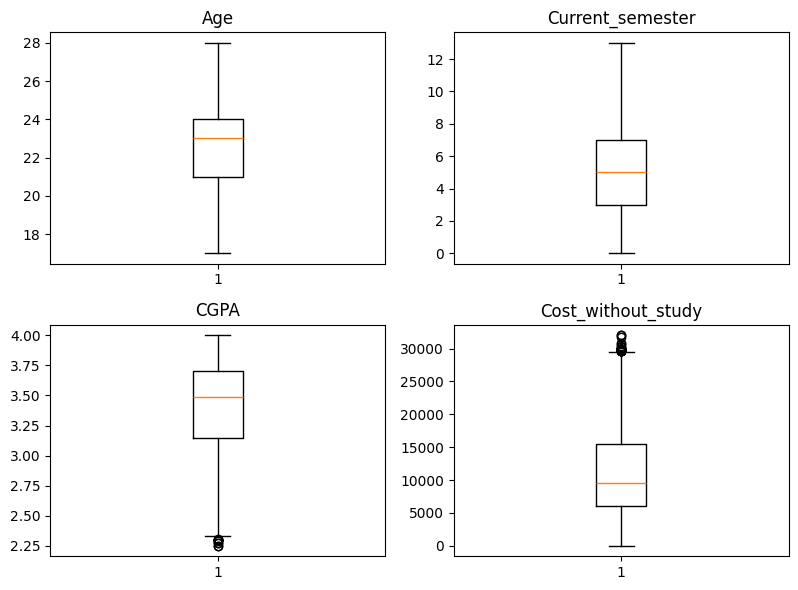

In [53]:
plt.figure(figsize=(8,6))
for i,col in enumerate(num_cols,1):
  plt.subplot(2,2,i)
  plt.boxplot(df[col])
  plt.title(col)
plt.tight_layout()
plt.show()

In [54]:
Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)
IQR = Q3 - Q1
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
df[num_cols] = df[num_cols].clip(lower=lower_limit, upper=upper_limit, axis=1)

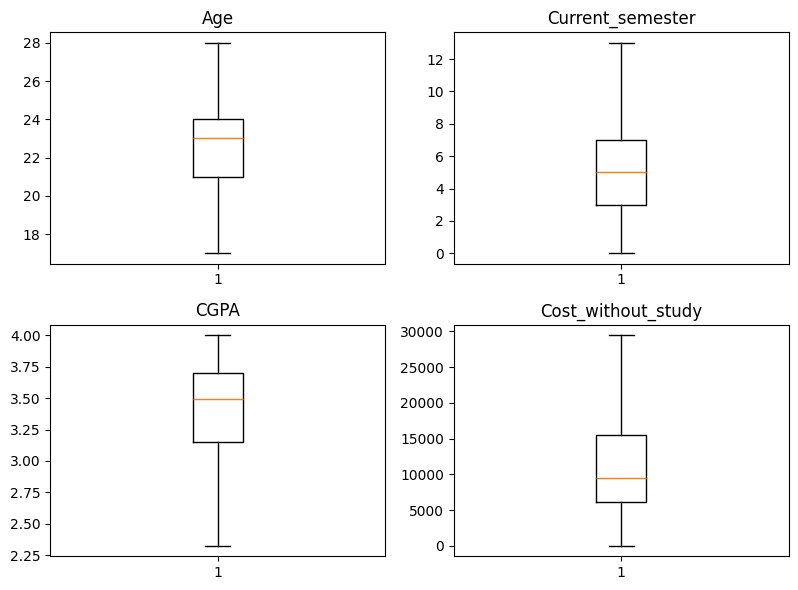

In [55]:
plt.figure(figsize=(8,6))
for i,col in enumerate(num_cols,1):
  plt.subplot(2,2,i)
  plt.boxplot(df[col])
  plt.title(col)
plt.tight_layout()
plt.show()


#
New Dataframe--> divide into numerical and categorical columns-->

num_df-->missing values-->duplicates-->standard scalar

cat_df-->missing values-->duplicates-->encoding

In [56]:
num_df=df.select_dtypes(include=['number']).columns
cat_df=df.select_dtypes(include=['object']).columns

In [57]:
df.isna().sum()

,0
Gender,0
Age,0
Family_background,0
Relationship_status,0
Marital_status,0
Living_style,0
Current_semester,0
CGPA,0
friend_circle,0
Health_condition,0


In [58]:
df.duplicated().sum()

np.int64(0)

#
Target Encoding - Label Encoding

In [59]:
print(df['Depression'].unique())
label_encoder=LabelEncoder()
df['Depression']=label_encoder.fit_transform(df['Depression'])
df.head()


['Yes' 'No']


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113.0,Chittagong,1
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815.0,Chittagong,1
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450.0,Dhaka,1
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413.0,Dhaka,0
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693.0,Dhaka,1


#
Columns with order--> Ordinal Encoding

In [60]:
df['Health_condition'].unique()

array(['Critical', 'Abnormal', 'Good', 'Normal'], dtype=object)

In [61]:
encoder_health= OrdinalEncoder(
    categories=[['Normal', 'Good', 'Abnormal','Critical']]
)
df['Health_condition']=encoder_health.fit_transform(df[['Health_condition']])
df.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,3.0,10113.0,Chittagong,1
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,2.0,13815.0,Chittagong,1
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,2.0,15450.0,Dhaka,1
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,1.0,17413.0,Dhaka,0
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,2.0,16693.0,Dhaka,1


In [62]:
df['Family_background'].unique()

array(['Middle class', 'Lower Middle class', 'Rich class'], dtype=object)

In [63]:
encoder_family= OrdinalEncoder(
    categories=[['Lower Middle class', 'Middle class', 'Rich class']]
)
df['Family_background']=encoder_family.fit_transform(df[['Family_background']])
df.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,1.0,Single,Unmarried,Bachelor,8,3.43,Yes,3.0,10113.0,Chittagong,1
1,Male,19,1.0,Single,Unmarried,Bachelor,2,3.70,Yes,2.0,13815.0,Chittagong,1
2,Male,23,1.0,Single,Unmarried,Family,8,3.28,No,2.0,15450.0,Dhaka,1
3,Male,20,1.0,Complicated,Unmarried,Family,2,3.77,No,1.0,17413.0,Dhaka,0
4,Female,21,1.0,Single,Unmarried,Family,1,4.00,No,2.0,16693.0,Dhaka,1


In [64]:
df['Family_background'].unique()

array([1., 0., 2.])

#
One hot Encoder

In [65]:
encoder_gender= OneHotEncoder()
encoded_gender=encoder_gender.fit_transform(df[['Gender']])
encoded_df=pd.DataFrame(
    encoded_gender.toarray(),
    columns=encoder_gender.get_feature_names_out(['Gender']),
    index=df.index
)
print(encoded_df.head())

df=pd.concat([df.drop('Gender',axis=1),encoded_df],axis=1)

   Gender_Female  Gender_Male
0            1.0          0.0
1            0.0          1.0
2            0.0          1.0
3            0.0          1.0
4            1.0          0.0


In [66]:
encoder_rtln= OneHotEncoder()
encoded_rtln=encoder_rtln.fit_transform(df[['Relationship_status']])
encoded_df=pd.DataFrame(
    encoded_rtln.toarray(),
    columns=encoder_rtln.get_feature_names_out(['Relationship_status']),
    index=df.index
)
print(encoded_df.head())

   Relationship_status_Complicated  Relationship_status_In a Relationship  \
0                              0.0                                    0.0   
1                              0.0                                    0.0   
2                              0.0                                    0.0   
3                              1.0                                    0.0   
4                              0.0                                    0.0   

   Relationship_status_Single  
0                         1.0  
1                         1.0  
2                         1.0  
3                         0.0  
4                         1.0  


In [67]:
df=pd.concat([df.drop('Relationship_status',axis=1),encoded_df],axis=1)


In [68]:
df.head()

,Age,Family_background,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression,Gender_Female,Gender_Male,Relationship_status_Complicated,Relationship_status_In a Relationship,Relationship_status_Single
0,22,1.0,Unmarried,Bachelor,8,3.43,Yes,3.0,10113.0,Chittagong,1,1.0,0.0,0.0,0.0,1.0
1,19,1.0,Unmarried,Bachelor,2,3.70,Yes,2.0,13815.0,Chittagong,1,0.0,1.0,0.0,0.0,1.0
2,23,1.0,Unmarried,Family,8,3.28,No,2.0,15450.0,Dhaka,1,0.0,1.0,0.0,0.0,1.0
3,20,1.0,Unmarried,Family,2,3.77,No,1.0,17413.0,Dhaka,0,0.0,1.0,1.0,0.0,0.0
4,21,1.0,Unmarried,Family,1,4.00,No,2.0,16693.0,Dhaka,1,1.0,0.0,0.0,0.0,1.0


In [69]:
encoder_marital=OneHotEncoder()
encoded_marital=encoder_marital.fit_transform(df[['Marital_status']])
encoded_df=pd.DataFrame(
    encoded_marital.toarray(),
    columns=encoder_marital.get_feature_names_out(['Marital_status']),
    index=df.index
)
df=pd.concat([df.drop('Marital_status',axis=1),encoded_df],axis=1)


In [70]:
df.head()

,Age,Family_background,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression,Gender_Female,Gender_Male,Relationship_status_Complicated,Relationship_status_In a Relationship,Relationship_status_Single,Marital_status_Married,Marital_status_Separated,Marital_status_Unmarried
0,22,1.0,Bachelor,8,3.43,Yes,3.0,10113.0,Chittagong,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
1,19,1.0,Bachelor,2,3.70,Yes,2.0,13815.0,Chittagong,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
2,23,1.0,Family,8,3.28,No,2.0,15450.0,Dhaka,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
3,20,1.0,Family,2,3.77,No,1.0,17413.0,Dhaka,0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
4,21,1.0,Family,1,4.00,No,2.0,16693.0,Dhaka,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0


In [71]:
encoder_liv=OneHotEncoder()
encoded_liv=encoder_liv.fit_transform(df[['Living_style']])
encoded_df=pd.DataFrame(
    encoded_liv.toarray(),
    columns=encoder_liv.get_feature_names_out(['Living_style']),
    index=df.index
)
print(encoded_df.head())
df=pd.concat([df.drop('Living_style',axis=1),encoded_df],axis=1)
df.head()


   Living_style_Bachelor  Living_style_Family
0                    1.0                  0.0
1                    1.0                  0.0
2                    0.0                  1.0
3                    0.0                  1.0
4                    0.0                  1.0


,Age,Family_background,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression,Gender_Female,Gender_Male,Relationship_status_Complicated,Relationship_status_In a Relationship,Relationship_status_Single,Marital_status_Married,Marital_status_Separated,Marital_status_Unmarried,Living_style_Bachelor,Living_style_Family
0,22,1.0,8,3.43,Yes,3.0,10113.0,Chittagong,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
1,19,1.0,2,3.70,Yes,2.0,13815.0,Chittagong,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
2,23,1.0,8,3.28,No,2.0,15450.0,Dhaka,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
3,20,1.0,2,3.77,No,1.0,17413.0,Dhaka,0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
4,21,1.0,1,4.00,No,2.0,16693.0,Dhaka,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0


In [72]:
encoder_frnd=OneHotEncoder()
encoded_frnd=encoder_frnd.fit_transform(df[['friend_circle']])
encoded_df=pd.DataFrame(
    encoded_frnd.toarray(),
    columns=encoder_frnd.get_feature_names_out(['friend_circle']),
    index=df.index
)
print(encoded_df.head())
df=pd.concat([df.drop('friend_circle',axis=1),encoded_df],axis=1)
df.head()


   friend_circle_No  friend_circle_Yes
0               0.0                1.0
1               0.0                1.0
2               1.0                0.0
3               1.0                0.0
4               1.0                0.0


,Age,Family_background,Current_semester,CGPA,Health_condition,Cost_without_study,Home_division,Depression,Gender_Female,Gender_Male,Relationship_status_Complicated,Relationship_status_In a Relationship,Relationship_status_Single,Marital_status_Married,Marital_status_Separated,Marital_status_Unmarried,Living_style_Bachelor,Living_style_Family,friend_circle_No,friend_circle_Yes
0,22,1.0,8,3.43,3.0,10113.0,Chittagong,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0
1,19,1.0,2,3.70,2.0,13815.0,Chittagong,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0
2,23,1.0,8,3.28,2.0,15450.0,Dhaka,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0
3,20,1.0,2,3.77,1.0,17413.0,Dhaka,0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0
4,21,1.0,1,4.00,2.0,16693.0,Dhaka,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0


In [73]:
encoder_home=OneHotEncoder()
encoded_home=encoder_home.fit_transform(df[['Home_division']])
encoded_df=pd.DataFrame(
    encoded_home.toarray(),
    columns=encoder_home.get_feature_names_out(['Home_division']),
    index=df.index
)
print(encoded_df.head())
df=pd.concat([df.drop('Home_division',axis=1),encoded_df],axis=1)
df.head()


   Home_division_Barisal  Home_division_Chittagong  Home_division_Dhaka  \
0                    0.0                       1.0                  0.0   
1                    0.0                       1.0                  0.0   
2                    0.0                       0.0                  1.0   
3                    0.0                       0.0                  1.0   
4                    0.0                       0.0                  1.0   

   Home_division_Khulna  Home_division_Mymensingh  Home_division_Rajshahi  \
0                   0.0                       0.0                     0.0   
1                   0.0                       0.0                     0.0   
2                   0.0                       0.0                     0.0   
3                   0.0                       0.0                     0.0   
4                   0.0                       0.0                     0.0   

   Home_division_Rangpur  Home_division_Sylhet  
0                    0.0             

,Age,Family_background,Current_semester,CGPA,Health_condition,Cost_without_study,Depression,Gender_Female,Gender_Male,Relationship_status_Complicated,...,friend_circle_No,friend_circle_Yes,Home_division_Barisal,Home_division_Chittagong,Home_division_Dhaka,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet
0,22,1.0,8,3.43,3.0,10113.0,1,1.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,19,1.0,2,3.70,2.0,13815.0,1,0.0,1.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,23,1.0,8,3.28,2.0,15450.0,1,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,20,1.0,2,3.77,1.0,17413.0,0,0.0,1.0,1.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,21,1.0,1,4.00,2.0,16693.0,1,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


#
Splitting Train and Test Data

In [74]:

X=df.drop('Depression',axis=1)
y=df['Depression']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(3571, 26)
(893, 26)
(3571,)
(893,)


In [75]:

print(X_train.head())
scaler=StandardScaler()
X_train_scaled=X_train.copy()
X_test_scaled=X_test.copy()
X_train_scaled[num_cols]=scaler.fit_transform(X_train[num_cols])# numpy array
X_test_scaled[num_cols]=scaler.transform(X_test[num_cols])
X_train_scaled=pd.DataFrame(X_train_scaled,columns=X_train.columns, index=X_train.index)
X_test_scaled=pd.DataFrame(X_test_scaled,columns=X_test.columns, index=X_test.index)
print(X_train_scaled.head())

      Age  Family_background  Current_semester  CGPA  Health_condition  \
3918   20                1.0                 8  3.00               2.0   
2807   23                1.0                 4  3.39               0.0   
1406   22                0.0                 5  3.58               1.0   
3154   24                0.0                 3  3.84               1.0   
2598   22                1.0                 3  4.00               1.0   

      Cost_without_study  Gender_Female  Gender_Male  \
3918             15091.0            0.0          1.0   
2807              5900.0            1.0          0.0   
1406              5000.0            0.0          1.0   
3154              9000.0            1.0          0.0   
2598              4800.0            1.0          0.0   

      Relationship_status_Complicated  Relationship_status_In a Relationship  \
3918                              0.0                                    0.0   
2807                              0.0                     